# Netflix Options around the Q4 2024 Earnings Announcement

*Nova SBE, Derivatives (2026).*

Netflix reported Q4 2024 earnings after the close on 21 Jan 2025. Using OptionMetrics quotes from 29 Nov 2024 to 27 Feb 2025, this notebook asks how option prices react to the announcement and how well delta hedging replicates a call across it.

1. **Implied volatility:** the smile for one expiry, the ATM term structure, and the daily IV level and skew.
2. **Risk-neutral densities:** Breeden–Litzenberger densities before and after earnings, compared with the Black–Scholes lognormal.
3. **Delta hedging:** a call whose path spans the announcement, hedged daily and weekly.

The analysis functions live in [`quantfin/options.py`](../src/quantfin/options.py) and [`quantfin/black_scholes.py`](../src/quantfin/black_scholes.py); this notebook loads the data, calls them and shows the results.

The data is licensed (WRDS) and not included. To run the notebook, place the export as `NFLX_Q2_2425.csv` next to it.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.stats import pearsonr, spearmanr

from quantfin.options import (
    atm_term_structure,
    density_stats,
    extract_rnd,
    first_date_after,
    fit_smile,
    iv_level_and_skew,
    last_date_before,
    quotes_on,
    select_hedge_contract,
    simulate_delta_hedge,
    unhedged_error,
)

FIGS_DIR = "figs"
os.makedirs(FIGS_DIR, exist_ok=True)
earnings_date = pd.Timestamp("2025-01-21")

# Netflix colour palette (white-background presentation)
NF_RED = "#E50914"
NF_DARK = "#221F1F"  # near-black for primary non-red lines
NF_GRAY1 = "#555555"  # secondary lines / weekly series
NF_GRAY2 = "#999999"  # reference / earnings lines

## Data preparation

Parse dates, and add days to expiry and moneyness $S/K$ (`prepare_quotes`). Sections 1 and 2 work on a copy without the identifier columns; section 3 tracks single contracts and keeps them.

In [2]:
from quantfin.options import prepare_quotes

quotes = prepare_quotes(pd.read_csv("NFLX_Q2_2425.csv"))
data = quotes.drop(columns=["secid", "symbol", "optionid", "ticker"])

data.describe().round(2).T

,count,mean,min,25%,50%,75%,max,std
date,264817,2025-01-14 22:54:59.199069,2024-11-29 00:00:00,2024-12-20 00:00:00,2025-01-16 00:00:00,2025-02-07 00:00:00,2025-02-27 00:00:00,NaN
exdate,264817,2025-08-10 22:29:21.847615,2024-12-06 00:00:00,2025-02-14 00:00:00,2025-04-17 00:00:00,2025-12-19 00:00:00,2027-01-15 00:00:00,NaN
strike_price,264817.0,746.35,5.0,530.0,755.0,960.0,2000.0,315.84
volume,264817.0,23.9,0.0,0.0,0.0,1.0,35077.0,239.58
impl_volatility,264817.0,0.61,0.15,0.35,0.41,0.62,8.99,0.59
delta,264817.0,0.24,-1.0,-0.07,0.0,0.89,1.0,0.58
gamma,264817.0,0.0,0.0,0.0,0.0,0.0,0.04,0.0
vega,264817.0,109.99,0.0,10.47,50.5,167.38,585.05,132.51
theta,264817.0,-76.17,-2283.74,-88.77,-50.14,-24.86,16.4,103.01
option_price,264817.0,166.09,0.0,3.45,67.75,264.5,1058.0,212.79


In [3]:
# Date-expiry pair with the most quotes
counts = data.groupby(["date", "exdate"]).size().sort_values(ascending=False)
p2_date, p2_exdate = counts.index[0]
print(f"date: {p2_date.date()}  |  exdate: {p2_exdate.date()}  |  rows: {counts.iloc[0]}")

date: 2024-12-24  |  exdate: 2025-01-17  |  rows: 426


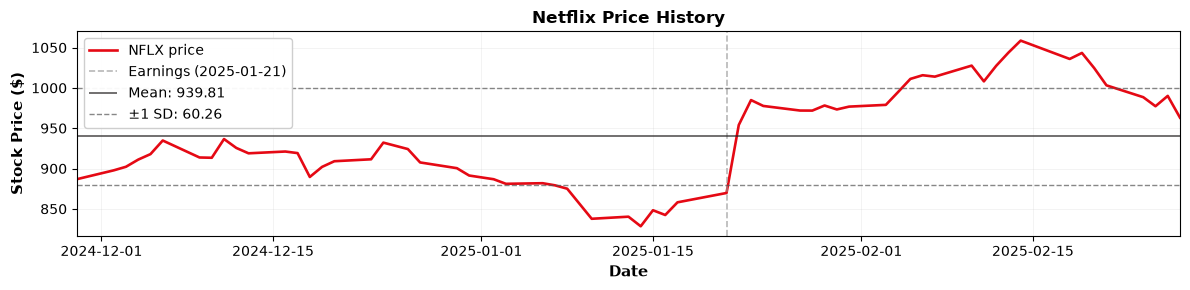

In [4]:
stock_ts = data.groupby("date", as_index=False)["stock_price"].first().sort_values("date")
ts_mean = stock_ts["stock_price"].mean()
ts_std = stock_ts["stock_price"].std()

fig, ax = plt.subplots(figsize=(12, 3))
ax.plot(stock_ts["date"], stock_ts["stock_price"], color=NF_RED, linewidth=1.9, label="NFLX price")
ax.axvline(
    earnings_date,
    color=NF_GRAY2,
    linewidth=1.2,
    linestyle="--",
    alpha=0.7,
    label="Earnings (2025-01-21)",
)
ax.hlines(
    ts_mean,
    stock_ts["date"].min(),
    stock_ts["date"].max(),
    color=NF_DARK,
    linewidth=1.2,
    linestyle="-",
    alpha=0.75,
    label=f"Mean: {ts_mean:.2f}",
)
ax.hlines(
    [ts_mean - ts_std, ts_mean + ts_std],
    stock_ts["date"].min(),
    stock_ts["date"].max(),
    color=NF_GRAY1,
    linewidth=1.0,
    linestyle="--",
    alpha=0.7,
    label=f"±1 SD: {ts_std:.2f}",
)

ax.set_xlabel("Date", fontsize=11, fontweight="bold")
ax.set_ylabel("Stock Price ($)", fontsize=11, fontweight="bold")
ax.set_title("Netflix Price History", fontsize=12, fontweight="bold")
ax.legend(fontsize=10, framealpha=0.95, loc="upper left")
ax.set_xlim(stock_ts["date"].min(), stock_ts["date"].max())
ax.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)
plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "nflx_price_history.svg"), format="svg", bbox_inches="tight", dpi=150
)
plt.show()

## 1. Implied volatility: smile, term structure and skew

### 1.1 Smile for a single expiry

24 Dec 2024, expiry 17 Jan 2025: the date-expiry pair with the most traded quotes. The left panel shows all strikes up to $S/K = 3$, the right panel the near-the-money window $S/K \in [0.9, 1.1]$.

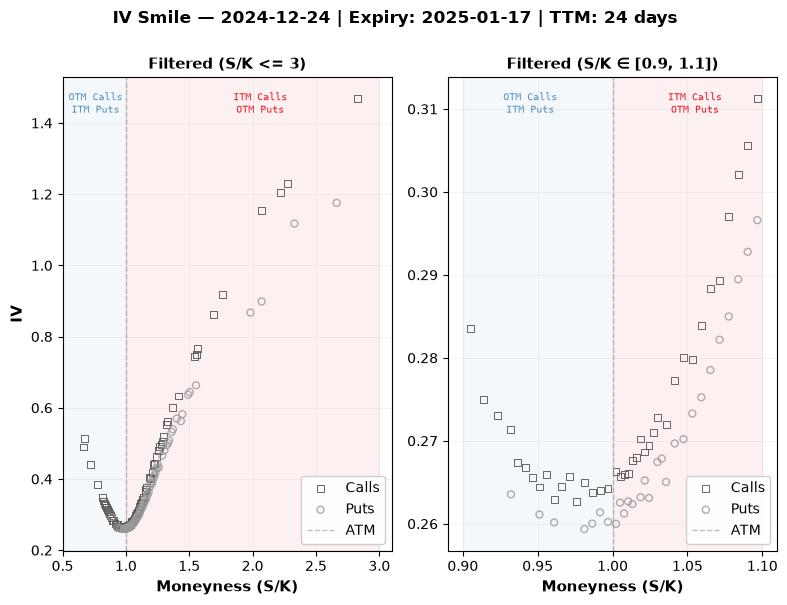

In [5]:
chosen_date = "2024-12-24"
chosen_exdate = "2025-01-17"
FILTER_1 = 3
FILTER_2 = 0.9
FILTER_3 = 1.1
chosen_ttm_days = (pd.Timestamp(chosen_exdate) - pd.Timestamp(chosen_date)).days

day_data = data[
    (data["date"] == chosen_date)
    & (data["exdate"] == chosen_exdate)
    & (data["moneyness"] <= FILTER_1)
    & (data["volume"] > 0)
].sort_values("moneyness")

day_data_f = day_data[(day_data["moneyness"] >= FILTER_2) & (day_data["moneyness"] <= FILTER_3)]

fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(8, 6))

calls_all = day_data[day_data["cp_flag"] == "C"]
puts_all = day_data[day_data["cp_flag"] == "P"]
ax_l.scatter(
    calls_all["moneyness"],
    calls_all["impl_volatility"],
    marker="s",
    facecolors="none",
    edgecolors=NF_GRAY1,
    s=25,
    linewidths=0.7,
    label="Calls",
    alpha=0.9,
)
ax_l.scatter(
    puts_all["moneyness"],
    puts_all["impl_volatility"],
    marker="o",
    facecolors="none",
    edgecolors=NF_GRAY2,
    s=25,
    linewidths=1.0,
    label="Puts",
    alpha=0.8,
)
ax_l.axvline(1, color=NF_GRAY2, linestyle="--", linewidth=1.0, alpha=0.6, label="ATM")
ax_l.axvspan(0, 1, alpha=0.06, color="#4488BB", zorder=0)
ax_l.axvspan(1, FILTER_1, alpha=0.06, color=NF_RED, zorder=0)
ax_l.text(
    0.10,
    0.97,
    "OTM Calls\nITM Puts",
    transform=ax_l.transAxes,
    fontsize=7.5,
    ha="center",
    va="top",
    color="#4488BB",
    fontfamily="monospace",
    alpha=0.9,
)
ax_l.text(
    0.60,
    0.97,
    "ITM Calls\nOTM Puts",
    transform=ax_l.transAxes,
    fontsize=7.5,
    ha="center",
    va="top",
    color=NF_RED,
    fontfamily="monospace",
    alpha=0.9,
)
ax_l.set_xlabel("Moneyness (S/K)", fontsize=11, fontweight="bold")
ax_l.set_ylabel("IV", fontsize=11, fontweight="bold")
ax_l.set_title(f"Filtered (S/K <= {FILTER_1})", fontsize=11, fontweight="bold")
ax_l.legend(fontsize=10, framealpha=0.95)
ax_l.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)
ax_l.set_xlim(0.5, FILTER_1 + 0.1)

calls_f = day_data_f[day_data_f["cp_flag"] == "C"]
puts_f = day_data_f[day_data_f["cp_flag"] == "P"]
ax_r.scatter(
    calls_f["moneyness"],
    calls_f["impl_volatility"],
    marker="s",
    facecolors="none",
    edgecolors=NF_GRAY1,
    s=25,
    linewidths=0.7,
    label="Calls",
    alpha=0.9,
)
ax_r.scatter(
    puts_f["moneyness"],
    puts_f["impl_volatility"],
    marker="o",
    facecolors="none",
    edgecolors=NF_GRAY2,
    s=25,
    linewidths=1.0,
    label="Puts",
    alpha=0.8,
)
ax_r.axvline(1, color=NF_GRAY2, linestyle="--", linewidth=1.0, alpha=0.6, label="ATM")
ax_r.axvspan(FILTER_2, 1, alpha=0.06, color="#4488BB", zorder=0)
ax_r.axvspan(1, FILTER_3, alpha=0.06, color=NF_RED, zorder=0)
ax_r.text(
    0.25,
    0.97,
    "OTM Calls\nITM Puts",
    transform=ax_r.transAxes,
    fontsize=7.5,
    ha="center",
    va="top",
    color="#4488BB",
    fontfamily="monospace",
    alpha=0.9,
)
ax_r.text(
    0.75,
    0.97,
    "ITM Calls\nOTM Puts",
    transform=ax_r.transAxes,
    fontsize=7.5,
    ha="center",
    va="top",
    color=NF_RED,
    fontfamily="monospace",
    alpha=0.9,
)
ax_r.set_xlabel("Moneyness (S/K)", fontsize=11, fontweight="bold")
ax_r.set_title(f"Filtered (S/K ∈ [{FILTER_2}, {FILTER_3}])", fontsize=11, fontweight="bold")
ax_r.legend(fontsize=10, framealpha=0.95)
ax_r.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)

fig.suptitle(
    f"IV Smile — {chosen_date} | Expiry: {chosen_exdate} | TTM: {chosen_ttm_days} days",
    fontsize=12,
    fontweight="bold",
    y=1.00,
)
plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "iv_smile.svg"), format="svg", bbox_inches="tight", dpi=150)
plt.show()

### 1.2 ATM term structure

For each expiry on the same date, take the call and the put closest to the money.

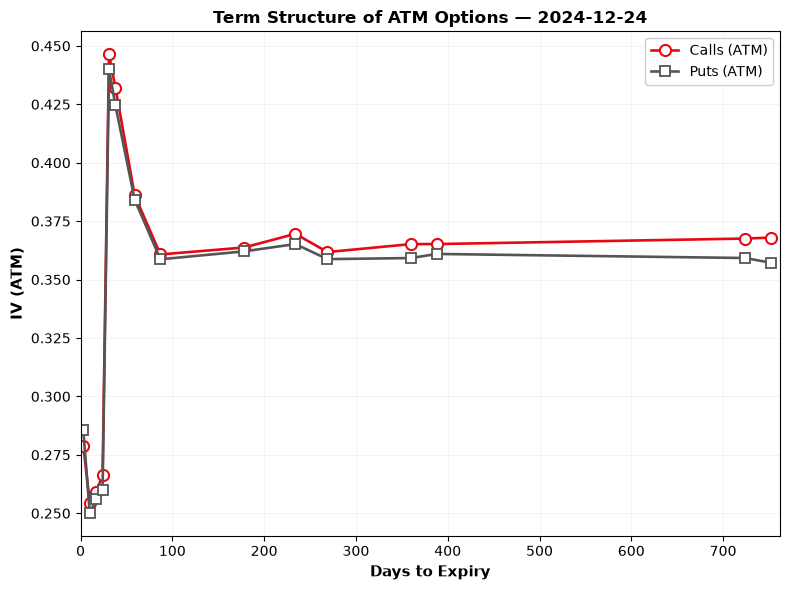

In [6]:
atm = atm_term_structure(data[data["date"] == chosen_date])
atm_calls_ts, atm_puts_ts = atm["C"], atm["P"]

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(
    atm_calls_ts["tte"],
    atm_calls_ts["iv_atm"],
    color=NF_RED,
    linewidth=1.9,
    marker="o",
    markersize=8,
    markerfacecolor="white",
    markeredgecolor=NF_RED,
    markeredgewidth=1.5,
    label="Calls (ATM)",
)
ax.plot(
    atm_puts_ts["tte"],
    atm_puts_ts["iv_atm"],
    color=NF_GRAY1,
    linewidth=1.9,
    marker="s",
    markersize=7,
    markerfacecolor="white",
    markeredgecolor=NF_GRAY1,
    markeredgewidth=1.3,
    label="Puts (ATM)",
)
ax.set_xlabel("Days to Expiry", fontsize=11, fontweight="bold")
ax.set_ylabel("IV (ATM)", fontsize=11, fontweight="bold")
ax.set_title(f"Term Structure of ATM Options — {chosen_date}", fontsize=12, fontweight="bold")
ax.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)
ax.legend(fontsize=10, framealpha=0.95)

tte_max = 10
if not atm_calls_ts.empty:
    tte_max = max(tte_max, float(atm_calls_ts["tte"].max()))
if not atm_puts_ts.empty:
    tte_max = max(tte_max, float(atm_puts_ts["tte"].max()))
ax.set_xlim(0, tte_max + 10)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "atm_term_structure.svg"), format="svg", bbox_inches="tight", dpi=150
)
plt.show()

### 1.3 Daily IV level and skew

Level is the mean IV of all traded options each day. Skew is the mean IV of OTM puts ($S/K > 1$) minus the mean IV of OTM calls ($S/K < 1$).

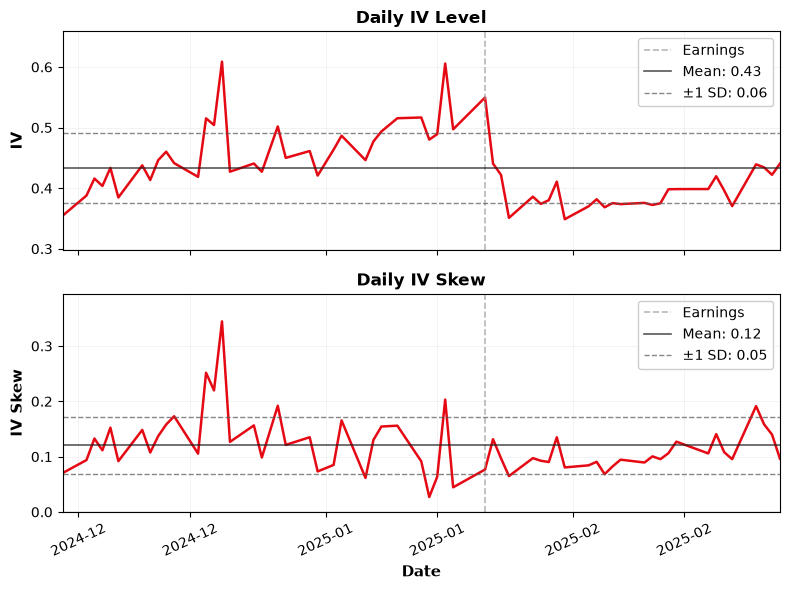

         level     skew
count  60.0000  60.0000
mean    0.4333   0.1204
std     0.0580   0.0521
min     0.3488   0.0269
25%     0.3856   0.0906
50%     0.4246   0.1059
75%     0.4618   0.1426
max     0.6088   0.3445


In [7]:
ts = iv_level_and_skew(data)
iv_level, iv_skew = ts["level"], ts["skew"]

avg_level = iv_level.mean()
std_level = iv_level.std()
avg_skew = iv_skew.mean()
std_skew = iv_skew.std()

ts = pd.concat([iv_level, iv_skew], axis=1)

fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(8, 6), sharex=True)

ax1.plot(ts.index, ts["level"], color=NF_RED, linewidth=1.8)
ax1.axvline(
    earnings_date, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7, label="Earnings"
)
ax1.axhline(
    avg_level,
    color=NF_DARK,
    linewidth=1.2,
    linestyle="-",
    alpha=0.75,
    label=f"Mean: {avg_level:.2f}",
)
ax1.axhline(
    avg_level + std_level,
    color=NF_GRAY1,
    linewidth=1.0,
    linestyle="--",
    alpha=0.7,
    label=f"±1 SD: {std_level:.2f}",
)
ax1.axhline(avg_level - std_level, color=NF_GRAY1, linewidth=1.0, linestyle="--", alpha=0.7)
ax1.set_ylabel("IV", fontsize=11, fontweight="bold")
ax1.set_title("Daily IV Level", fontsize=12, fontweight="bold")
ax1.legend(fontsize=10, framealpha=0.95, loc="upper right")
ax1.set_ylim(iv_level.min() - 0.05, iv_level.max() + 0.05)
ax1.set_xlim(iv_level.index.min(), iv_level.index.max())
ax1.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)

ax2.plot(ts.index, ts["skew"], color=NF_RED, linewidth=1.8)
ax2.axvline(
    earnings_date, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7, label="Earnings"
)
ax2.axhline(0, color=NF_GRAY1, linewidth=1.0, linestyle="-", alpha=0.5)
ax2.set_ylabel("IV Skew", fontsize=11, fontweight="bold")
ax2.set_title("Daily IV Skew", fontsize=12, fontweight="bold")
ax2.set_xlabel("Date", fontsize=11, fontweight="bold")
ax2.xaxis.set_major_formatter(plt.matplotlib.dates.DateFormatter("%Y-%m"))
ax2.axhline(
    avg_skew, color=NF_DARK, linewidth=1.2, linestyle="-", alpha=0.75, label=f"Mean: {avg_skew:.2f}"
)
ax2.axhline(
    avg_skew + std_skew,
    color=NF_GRAY1,
    linewidth=1.0,
    linestyle="--",
    alpha=0.7,
    label=f"±1 SD: {std_skew:.2f}",
)
ax2.axhline(avg_skew - std_skew, color=NF_GRAY1, linewidth=1.0, linestyle="--", alpha=0.7)
ax2.legend(fontsize=10, framealpha=0.95, loc="upper right")
ax2.set_ylim(0, iv_skew.max() + 0.05)
ax2.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)
ax2.tick_params(axis="x", rotation=25)

plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "iv_level_skew.svg"), format="svg", bbox_inches="tight", dpi=150)
plt.show()
print(ts.describe().round(4))

### 1.4 Do level and skew move together?

Pearson and Spearman correlations of the daily series, two-sided tests.

In [8]:
# Correlation + significance tests (two-sided)
tmp = ts[["level", "skew"]].dropna()
n_obs = len(tmp)

pearson_r, pearson_p = pearsonr(tmp["level"], tmp["skew"])
spearman_rho, spearman_p = spearmanr(tmp["level"], tmp["skew"])

print(f"n observations: {n_obs}")
print(f"pearson r(level, skew):   {pearson_r:.4f}  |  p-value: {pearson_p:.4g}")
print(f"spearman rho(level, skew): {spearman_rho:.4f}  |  p-value: {spearman_p:.4g}")

alpha = 0.05
print(f"pearson significant at 5%: {pearson_p < alpha}")
print(f"spearman significant at 5%: {spearman_p < alpha}")

n observations: 60
pearson r(level, skew):   0.5773  |  p-value: 1.375e-06
spearman rho(level, skew): 0.4661  |  p-value: 0.0001747
pearson significant at 5%: True
spearman significant at 5%: True


## 2. Risk-neutral densities around earnings

Pick the trading day closest to the announcement and the expiry with the most quotes on that day. The densities in 2.2 compare the last trading day before earnings with the first day after, for that same expiry.

In [9]:
# --- Earnings announcement date (or nearest trading day) ---
available_dates = counts.index.get_level_values("date").unique().sort_values()
p2_date = available_dates[np.abs(available_dates - earnings_date).argmin()]

counts_on_p2_date = counts[counts.index.get_level_values("date") == p2_date]
p2_date, p2_exdate = counts_on_p2_date.index[0]

print(f"Earnings date: {p2_date.date()}  |  Expiry: {p2_exdate.date()}")

Earnings date: 2025-01-21  |  Expiry: 2025-01-24


### 2.1 Smile fits before and after earnings

A quadratic in strike, fitted to call IVs over all traded strikes and shown on the window $S/K \in [0.75, 1.35]$.

In [10]:
SMILE_LOW, SMILE_HIGH = 0.75, 1.35  # moneyness window shown in the panels

pre_iv_date = last_date_before(data, p2_exdate, earnings_date)
post_iv_date = first_date_after(data, p2_exdate, earnings_date)


def smile_panel(date):
    # fit on all traded call strikes, evaluate on the near-ATM window
    calls = quotes_on(data, date, p2_exdate, cp_flag="C")
    smile = fit_smile(calls["strike_price"].to_numpy(), calls["impl_volatility"].to_numpy())
    near = calls[calls["moneyness"].between(SMILE_LOW, SMILE_HIGH)]
    grid = np.linspace(near["strike_price"].min(), near["strike_price"].max(), 500)
    return calls, near, grid, smile(grid)


calls_pre, near_pre, K_grid_pre_f, iv_grid_pre_f = smile_panel(pre_iv_date)
calls_post, near_post, K_grid_post_f, iv_grid_post_f = smile_panel(post_iv_date)

S_pre_iv, S_post_iv = calls_pre["stock_price"].iloc[0], calls_post["stock_price"].iloc[0]
iv_obs_pre_iv, iv_obs_post_iv = (
    calls_pre["impl_volatility"].values,
    calls_post["impl_volatility"].values,
)
K_obs_pre_f, iv_obs_pre_f = near_pre["strike_price"].values, near_pre["impl_volatility"].values
K_obs_post_f, iv_obs_post_f = near_post["strike_price"].values, near_post["impl_volatility"].values
ttm_days_pre_iv = (p2_exdate - pre_iv_date).days
ttm_days_post_iv = (p2_exdate - post_iv_date).days

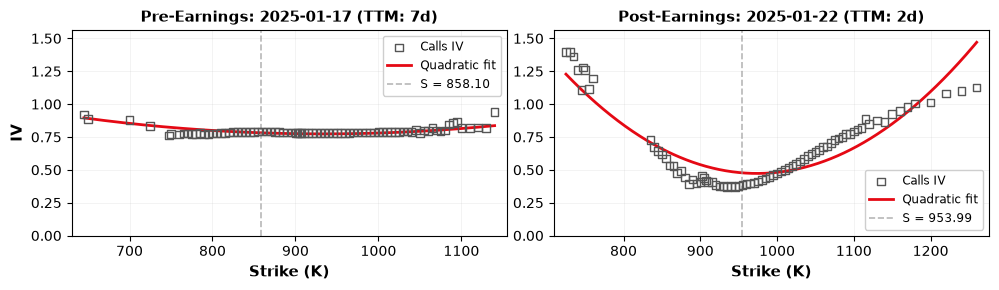

Pre-earnings:  2025-01-17 | TTM: 7d | S=858.10 | IV range: 76.1%–108.8%
Post-earnings: 2025-01-22 | TTM: 2d | S=953.99 | IV range: 36.9%–256.3%


In [11]:
def _plot_smile(ax, K_obs_, iv_obs_, K_grid_, iv_grid_, S_, title, ylabel=None, ylim=None):
    ax.scatter(
        K_obs_,
        iv_obs_,
        marker="s",
        facecolors="none",
        edgecolors=NF_GRAY1,
        s=30,
        linewidths=1.0,
        zorder=3,
        label="Calls IV",
    )
    ax.plot(K_grid_, iv_grid_, color=NF_RED, linewidth=2.0, label="Quadratic fit")
    ax.axvline(S_, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7, label=f"S = {S_:.2f}")
    ax.set_xlabel("Strike (K)", fontsize=11, fontweight="bold")
    if ylabel:
        ax.set_ylabel(ylabel, fontsize=11, fontweight="bold")
    ax.set_title(title, fontsize=11, fontweight="bold")
    ax.legend(fontsize=8.5, framealpha=0.95)
    _pad = (K_obs_.max() - K_obs_.min()) * 0.03
    ax.set_xlim(K_obs_.min() - _pad, K_obs_.max() + _pad)
    if ylim is not None:
        ax.set_ylim(*ylim)
    ax.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)


# Shared y-ceiling based on observed data so near-ATM curvature is visible
_ymax_f = max(iv_obs_pre_f.max(), iv_obs_post_f.max()) * 1.12

fig, (ax_tl, ax_tr) = plt.subplots(1, 2, figsize=(10, 3))

_plot_smile(
    ax_tl,
    K_obs_pre_f,
    iv_obs_pre_f,
    K_grid_pre_f,
    iv_grid_pre_f,
    S_pre_iv,
    f"Pre-Earnings: {pre_iv_date.date()} (TTM: {ttm_days_pre_iv}d)",
    ylabel="IV",
    ylim=(0, _ymax_f),
)
_plot_smile(
    ax_tr,
    K_obs_post_f,
    iv_obs_post_f,
    K_grid_post_f,
    iv_grid_post_f,
    S_post_iv,
    f"Post-Earnings: {post_iv_date.date()} (TTM: {ttm_days_post_iv}d)",
    ylim=(0, _ymax_f),
)

plt.tight_layout()
plt.savefig(os.path.join(FIGS_DIR, "p2_iv_fit.svg"), format="svg", bbox_inches="tight", dpi=150)
plt.show()

print(
    f"Pre-earnings:  {pre_iv_date.date()} | TTM: {ttm_days_pre_iv}d | S={S_pre_iv:.2f} | IV range: {iv_obs_pre_iv.min() * 100:.1f}%–{iv_obs_pre_iv.max() * 100:.1f}%"
)
print(
    f"Post-earnings: {post_iv_date.date()} | TTM: {ttm_days_post_iv}d | S={S_post_iv:.2f} | IV range: {iv_obs_post_iv.min() * 100:.1f}%–{iv_obs_post_iv.max() * 100:.1f}%"
)

### 2.2 Breeden–Litzenberger densities

The risk-neutral density is the discounted second derivative of the call price in strike:

$$f_Q(K) = e^{rT}\,\frac{\partial^2 C}{\partial K^2}.$$

`extract_rnd` prices calls with Black–Scholes on a fine strike grid using the fitted smile, lightly smoothed, then differentiated twice. Negative values are clipped, the outer 5% of each tail is tapered, and the density is rescaled to integrate to one. The dashed benchmark is the Black–Scholes lognormal at the ATM volatility.

In [12]:
near_date = last_date_before(data, p2_exdate, earnings_date)
post_date = first_date_after(data, p2_exdate, earnings_date)
near_exdate = post_exdate = p2_exdate
print(f"Pre-earnings: {near_date.date()}  |  Expiry: {near_exdate.date()}")
print(f"Post-earnings: {post_date.date()}  |  Expiry: {post_exdate.date()}")

# calls and puts, one quote per strike (the most traded)
df_near = quotes_on(data, near_date, near_exdate)
df_post = quotes_on(data, post_date, post_exdate)

S_near, r_near = df_near["stock_price"].iloc[0], df_near["rf"].iloc[0]
ttm_days_near = (near_exdate - near_date).days
T_near = ttm_days_near / 365
K_obs_near, iv_obs_near = df_near["strike_price"].values, df_near["impl_volatility"].values

S_post, r_post = df_post["stock_price"].iloc[0], df_post["rf"].iloc[0]
ttm_days_post = (post_exdate - post_date).days
T_post = ttm_days_post / 365
K_obs_post, iv_obs_post = df_post["strike_price"].values, df_post["impl_volatility"].values

Pre-earnings: 2025-01-17  |  Expiry: 2025-01-24
Post-earnings: 2025-01-22  |  Expiry: 2025-01-24


In [13]:
def annotate_rnd_panel(ax, K_grid, f_q, stats, stats_bs):
    m, s = stats["mean"], stats["std"]
    for n, alpha, lbl in [(3, 0.08, "±3σ"), (2, 0.14, "±2σ"), (1, 0.24, "±1σ")]:
        lo, hi = m - n * s, m + n * s
        msk = (K_grid >= lo) & (K_grid <= hi)
        ax.fill_between(K_grid[msk], f_q[msk], alpha=alpha, color=NF_RED, label=lbl, zorder=0)
    ax.axvline(
        stats["median"],
        color="#d01c8b",
        linewidth=1.2,
        linestyle=":",
        alpha=0.85,
        label=f"Median = {stats['median']:.0f}",
    )
    hdr = f"{'':14s}{'RND':>8s}{'BS':>8s}"
    sep = "\u2500" * 30
    txt = (
        f"{hdr}\n{sep}\n"
        f"{'Vol (ann.):':14s}{stats['sigma_rnd'] * 100:>7.1f}%{stats_bs['sigma_rnd'] * 100:>7.1f}%\n"
        f"{'Skewness:':14s}{stats['skew']:>8.2f}{stats_bs['skew']:>8.2f}\n"
        f"{'Kurtosis:':14s}{stats['kurt']:>8.2f}{stats_bs['kurt']:>8.2f}\n"
        f"{'Exc. Kurt:':14s}{stats['kurt_ex']:>8.2f}{stats_bs['kurt_ex']:>8.2f}\n"
        f"{'P(S_T>S_0):':14s}{stats['otm_prob'] * 100:>7.1f}%{stats_bs['otm_prob'] * 100:>7.1f}%"
    )
    ax.text(
        0.02,
        0.60,
        txt,
        transform=ax.transAxes,
        fontsize=8.5,
        verticalalignment="top",
        horizontalalignment="left",
        fontfamily="monospace",
        bbox=dict(boxstyle="round,pad=0.45", facecolor="white", alpha=0.90, edgecolor="#bbbbbb"),
    )

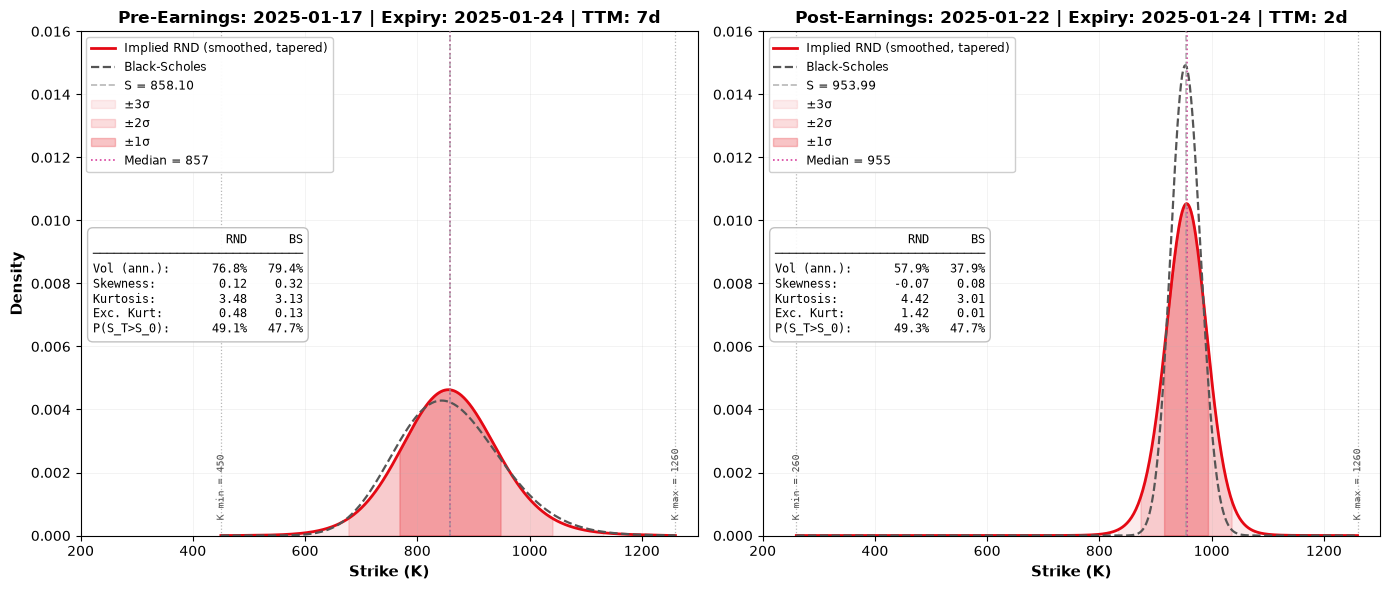

Pre-earnings:  2025-01-17  S=858.10   sigma_ATM=0.793   int_f_q=1.000
Post-earnings: 2025-01-22  S=953.99   sigma_ATM=0.379   int_f_q=1.000

=== RND Statistics ===

Pre-earnings 2025-01-17
  mean          : 858.4640
  std           : 91.2611
  sigma_rnd     : 0.7676
  median        : 857.4349
  skew          : 0.1170
  kurt          : 3.4760
  kurt_ex       : 0.4760
  otm_prob      : 0.4910

Post-earnings 2025-01-22
  mean          : 954.2550
  std           : 40.8785
  sigma_rnd     : 0.5787
  median        : 955.3908
  skew          : -0.0704
  kurt          : 4.4233
  kurt_ex       : 1.4233
  otm_prob      : 0.4928


In [14]:
rnd_near = extract_rnd(K_obs_near, iv_obs_near, S_near, r_near, T_near)
rnd_post = extract_rnd(K_obs_post, iv_obs_post, S_post, r_post, T_post)
K_grid_near, f_q_near, f_bs_near = rnd_near.strikes, rnd_near.density, rnd_near.lognormal
K_grid_post, f_q_post, f_bs_post = rnd_post.strikes, rnd_post.density, rnd_post.lognormal
sigma_atm_near, sigma_atm_post = rnd_near.sigma_atm, rnd_post.sigma_atm

stats_near = density_stats(K_grid_near, f_q_near, S_near, T_near)
stats_post = density_stats(K_grid_post, f_q_post, S_post, T_post)
stats_bs_near = density_stats(K_grid_near, f_bs_near, S_near, T_near)
stats_bs_post = density_stats(K_grid_post, f_bs_post, S_post, T_post)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6))

# --- Panel 1 (left): Near pre-earnings ---
ax1.plot(
    K_grid_near,
    f_q_near,
    color=NF_RED,
    linewidth=2.0,
    label="Implied RND (smoothed, tapered)",
    zorder=3,
)
ax1.plot(
    K_grid_near,
    f_bs_near,
    color=NF_GRAY1,
    linewidth=1.6,
    linestyle="--",
    label="Black-Scholes",
    zorder=3,
)
ax1.axvline(
    S_near,
    color=NF_GRAY2,
    linewidth=1.2,
    linestyle="--",
    alpha=0.7,
    label=f"S = {S_near:.2f}",
    zorder=3,
)
annotate_rnd_panel(ax1, K_grid_near, f_q_near, stats_near, stats_bs_near)
ax1.set_title(
    f"Pre-Earnings: {near_date.date()} | Expiry: {near_exdate.date()} | TTM: {ttm_days_near}d",
    fontsize=12,
    fontweight="bold",
)
ax1.set_xlabel("Strike (K)", fontsize=11, fontweight="bold")
ax1.set_ylabel("Density", fontsize=11, fontweight="bold")
ax1.set_ylim(0, 0.016)
ax1.set_xlim(200, 1300)
ax1.legend(fontsize=8.5, framealpha=0.95, ncol=1, loc="upper left")
ax1.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)
_y1 = ax1.get_ylim()[1]
for _K, _lbl in [(K_obs_near.min(), "K min"), (K_obs_near.max(), "K max")]:
    ax1.axvline(_K, color=NF_GRAY2, lw=0.9, ls=":", alpha=0.7, zorder=2)
    ax1.text(
        _K,
        _y1 * 0.03,
        f"{_lbl} = {_K:.0f}",
        rotation=90,
        ha="center",
        va="bottom",
        fontsize=7.5,
        color=NF_GRAY1,
        fontfamily="monospace",
    )

# --- Panel 2 (right): Post-earnings ---
ax2.plot(
    K_grid_post,
    f_q_post,
    color=NF_RED,
    linewidth=2.0,
    label="Implied RND (smoothed, tapered)",
    zorder=3,
)
ax2.plot(
    K_grid_post,
    f_bs_post,
    color=NF_GRAY1,
    linewidth=1.6,
    linestyle="--",
    label="Black-Scholes",
    zorder=3,
)
ax2.axvline(
    S_post,
    color=NF_GRAY2,
    linewidth=1.2,
    linestyle="--",
    alpha=0.7,
    label=f"S = {S_post:.2f}",
    zorder=3,
)
annotate_rnd_panel(ax2, K_grid_post, f_q_post, stats_post, stats_bs_post)
ax2.set_title(
    f"Post-Earnings: {post_date.date()} | Expiry: {post_exdate.date()} | TTM: {ttm_days_post}d",
    fontsize=12,
    fontweight="bold",
)
ax2.set_xlabel("Strike (K)", fontsize=11, fontweight="bold")
ax2.set_ylim(0, 0.016)
ax2.set_xlim(200, 1300)
ax2.legend(fontsize=8.5, framealpha=0.95, ncol=1, loc="upper left")
ax2.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)
_y2 = ax2.get_ylim()[1]
for _K, _lbl in [(K_obs_post.min(), "K min"), (K_obs_post.max(), "K max")]:
    ax2.axvline(_K, color=NF_GRAY2, lw=0.9, ls=":", alpha=0.7, zorder=2)
    ax2.text(
        _K,
        _y2 * 0.03,
        f"{_lbl} = {_K:.0f}",
        rotation=90,
        ha="center",
        va="bottom",
        fontsize=7.5,
        color=NF_GRAY1,
        fontfamily="monospace",
    )

plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "p2_rnd_comparison.svg"), format="svg", bbox_inches="tight", dpi=150
)
plt.show()

print(
    f"Pre-earnings:  {near_date.date()}  S={S_near:.2f}   sigma_ATM={sigma_atm_near:.3f}   int_f_q={np.trapezoid(f_q_near, K_grid_near):.3f}"
)
print(
    f"Post-earnings: {post_date.date()}  S={S_post:.2f}   sigma_ATM={sigma_atm_post:.3f}   int_f_q={np.trapezoid(f_q_post, K_grid_post):.3f}"
)
print()
print("=== RND Statistics ===")
for lbl, st in [
    (f"Pre-earnings {near_date.date()}", stats_near),
    (f"Post-earnings {post_date.date()}", stats_post),
]:
    print(f"\n{lbl}")
    for k, v in st.items():
        print(f"  {k:<14}: {v:.4f}")

## 3. Delta hedging a call across the announcement

Sell one call and hold delta shares, financing the difference at the risk-free rate. Compare rebalancing every trading day with every fifth, using OptionMetrics deltas. The terminal hedging error is the hedge portfolio's value at expiry minus the option payoff.

In [15]:
# contracts with an IV, a delta and a price on every observation
p3 = quotes.dropna(subset=["impl_volatility", "delta", "option_price"])
print(
    f"p3 shape: {p3.shape}  |  date range: {p3['date'].min().date()} to {p3['date'].max().date()}"
)

p3 shape: (264817, 19)  |  date range: 2024-11-29 to 2025-02-27


### 3.1 Contract selection

Search start dates 15–40 days before earnings for a call with about 30 days to expiry whose observed path has the announcement as close to its midpoint as possible. Ties go to the more liquid contract.

In [16]:
selection = select_hedge_contract(p3, earnings_date, cp_flag="C", ttm_window=(25, 35))
selected, path, start_date = selection.contract, selection.path, selection.start_date

K_sel = float(selected["strike_price"])
CP_sel = selected["cp_flag"]
earnings_obs_idx = int(np.flatnonzero(path["date"] == earnings_date)[0])

print("Selected contract")
print(
    f"Type={CP_sel} | Strike={K_sel:.2f} | Exdate={selected['exdate'].date()} | OptionID={int(selected['optionid'])}"
)
print(
    f"Start date={start_date.date()} | Path dates: {path['date'].min().date()} to {path['date'].max().date()} | N={len(path)}"
)
print(
    f"Earnings position in path: observation #{earnings_obs_idx} / {len(path)} (centered: {len(path) / 2:.1f})"
)
print(
    f"Initial TTM={int(path.loc[0, 'time2exp'])} days | Liquidity along path: total volume={path['volume'].sum():.0f}"
)

print("\n--- Top 5 candidates (sorted by centering) ---")
selection.candidates.head(5)[
    ["optionid", "strike_price", "exdate", "n_obs", "centering_error", "vol_sum"]
]

Selected contract
Type=C | Strike=700.00 | Exdate=2025-02-07 | OptionID=166454971
Start date=2025-01-06 | Path dates: 2025-01-06 to 2025-02-03 | N=18
Earnings position in path: observation #9 / 18 (centered: 9.0)
Initial TTM=32 days | Liquidity along path: total volume=16

--- Top 5 candidates (sorted by centering) ---


,optionid,strike_price,exdate,n_obs,centering_error,vol_sum
149,166454971,700.0,2025-02-07,18,0.0,16.0
147,166454969,680.0,2025-02-07,18,0.0,10.0
156,166454978,770.0,2025-02-07,18,0.0,3.0
140,166551038,610.0,2025-02-07,18,0.0,2.0
151,166454973,720.0,2025-02-07,18,0.0,2.0


### 3.2 Hedging engine

`simulate_delta_hedge`: at each rebalancing date the share position is reset to the current delta and the cash account absorbs the trade. Cash accrues at the risk-free rate between observations.

In [17]:
p3_daily, stats_daily = simulate_delta_hedge(path, K_sel, CP_sel, rebalance_step=1)
p3_weekly, stats_weekly = simulate_delta_hedge(path, K_sel, CP_sel, rebalance_step=5)

summary = pd.DataFrame(
    {
        "Daily": stats_daily,
        "Weekly": stats_weekly,
    }
).round(6)
summary

,Daily,Weekly
n_obs,18.000000,18.000000
n_rebalances,17.000000,4.000000
terminal_portfolio,279.027503,273.568303
terminal_payoff,278.940000,278.940000
terminal_error,0.087503,-5.371697
terminal_abs_error,0.087503,5.371697
terminal_error_pct_premium,0.000464,-0.028505
rmse_path_error,1.148927,4.112695


In [18]:
# Unhedged benchmark: sell the call and hold the premium in cash at the risk-free rate
unhedged = unhedged_error(path, K_sel, CP_sel)
unhedged_pct = unhedged / float(path.loc[0, "option_price"])
print(f"Unhedged terminal error: {unhedged:.2f} ({unhedged_pct * 100:.2f}% of premium)")

Unhedged terminal error: -89.87 (-47.69% of premium)


### 3.3 Results

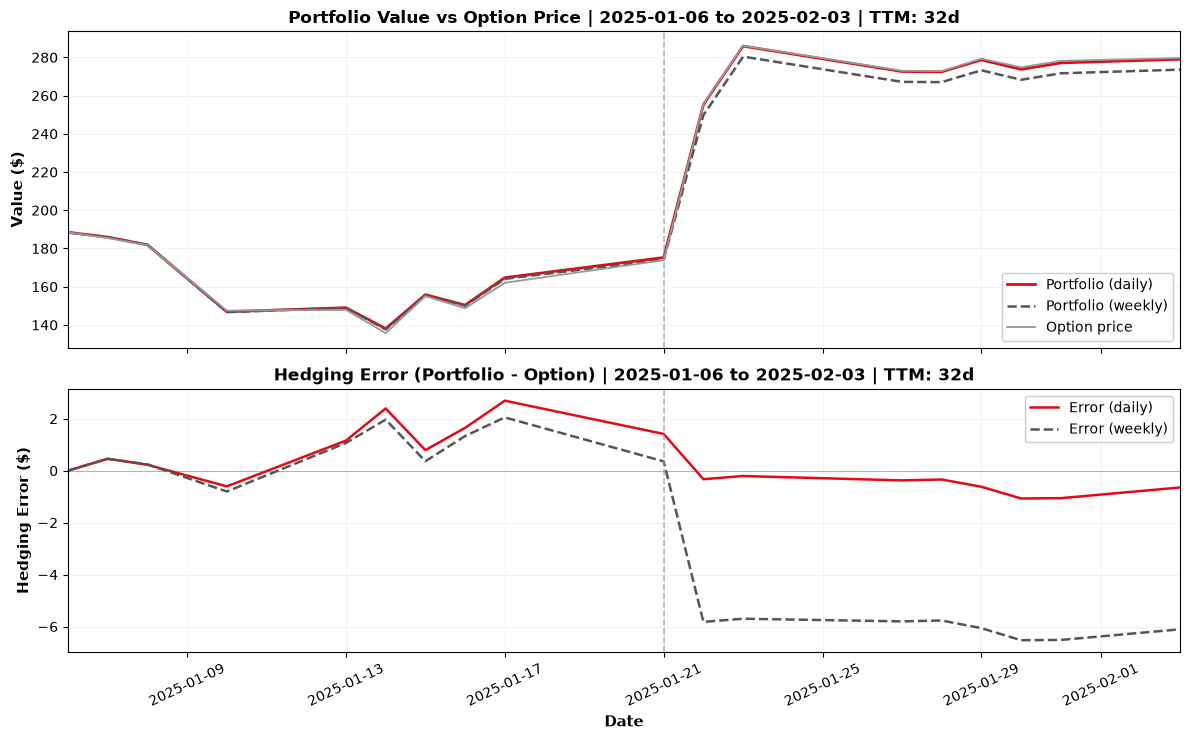

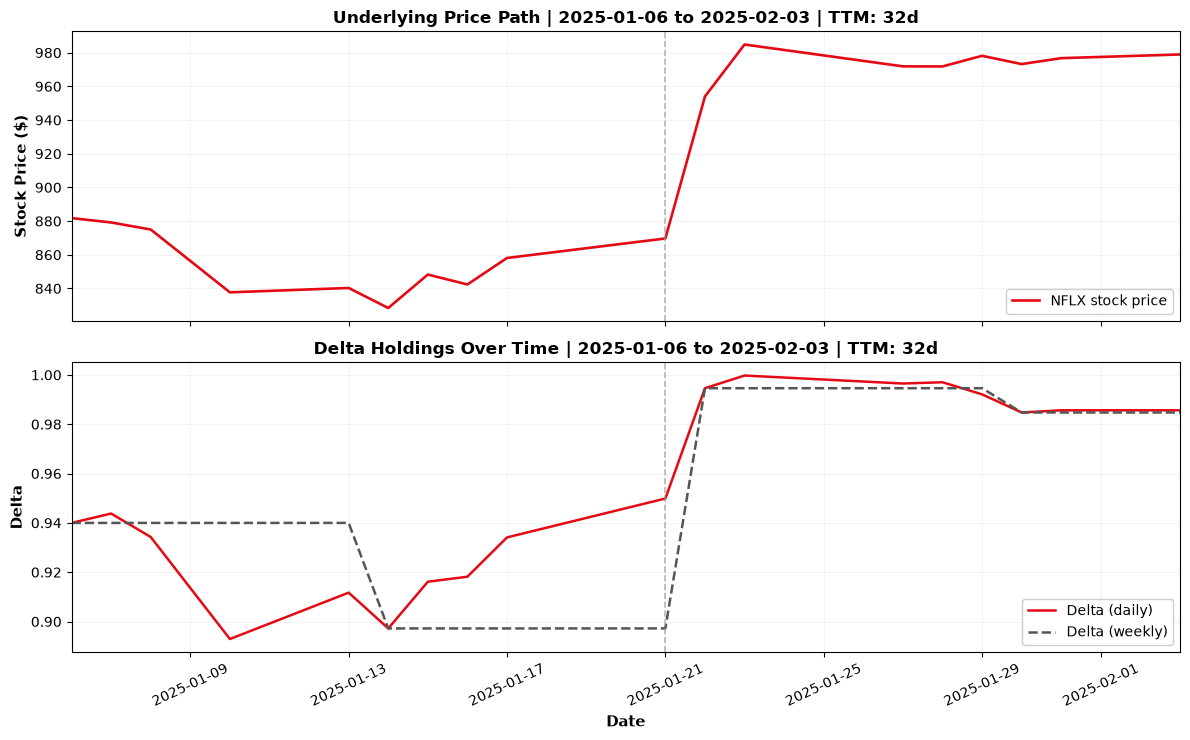

Hedging summary
                             Daily  Weekly
n_obs                        18.00   18.00
n_rebalances                 17.00    4.00
terminal_portfolio          279.03  273.57
terminal_payoff             278.94  278.94
terminal_error                0.09   -5.37
terminal_abs_error            0.09    5.37
terminal_error_pct_premium    0.00   -0.03
rmse_path_error               1.15    4.11


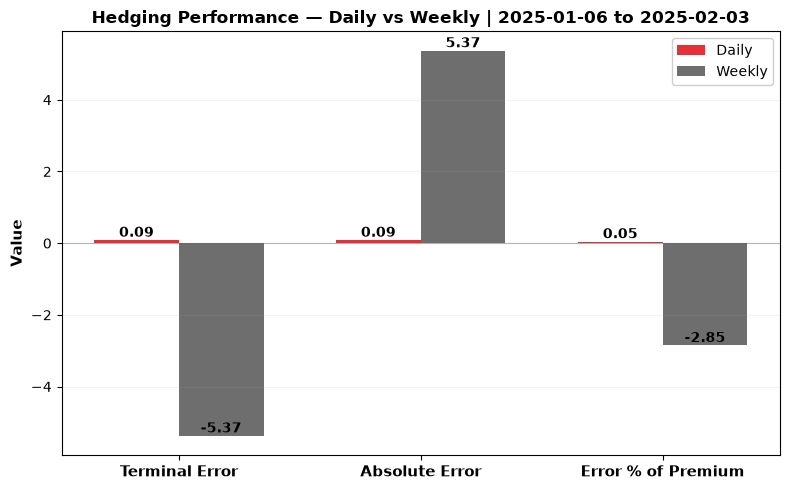


--- Verification of error metrics ---
Daily terminal error: 0.09
Daily initial option price: 188.45
Daily error % of premium: 0.05%

Weekly terminal error: -5.37
Weekly initial option price: 188.45
Weekly error % of premium: -2.85%


In [19]:
p3_start_date = path["date"].min().date()
p3_end_date = path["date"].max().date()
p3_ttm_start = int(path.loc[0, "time2exp"])
date_min = path["date"].min()
date_max = path["date"].max()

# Figure A: portfolio value + hedging error
fig_a, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.2, 1.0]}
)

# Panel 1: Portfolio value
ax1.plot(
    p3_daily["date"],
    p3_daily["portfolio_value"],
    color=NF_RED,
    linewidth=2.0,
    label="Portfolio (daily)",
)
ax1.plot(
    p3_weekly["date"],
    p3_weekly["portfolio_value"],
    color=NF_GRAY1,
    linewidth=1.8,
    linestyle="--",
    label="Portfolio (weekly)",
)
ax1.plot(
    p3_daily["date"], p3_daily["option_price"], color=NF_GRAY2, linewidth=1.3, label="Option price"
)
ax1.axvline(earnings_date, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7)
ax1.set_ylabel("Value ($)", fontsize=11, fontweight="bold")
ax1.set_title(
    f"Portfolio Value vs Option Price | {p3_start_date} to {p3_end_date} | TTM: {p3_ttm_start}d",
    fontsize=12,
    fontweight="bold",
)
ax1.legend(loc="lower right", fontsize=10, framealpha=0.95)
ax1.set_xlim(date_min, date_max)
ax1.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)

# Panel 2: Hedging error
ax2.plot(
    p3_daily["date"], p3_daily["hedging_error"], color=NF_RED, linewidth=1.8, label="Error (daily)"
)
ax2.plot(
    p3_weekly["date"],
    p3_weekly["hedging_error"],
    color=NF_GRAY1,
    linewidth=1.8,
    linestyle="--",
    label="Error (weekly)",
)
ax2.axhline(0, color=NF_GRAY1, linewidth=0.8, linestyle="-", alpha=0.4)
ax2.axvline(earnings_date, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7)
ax2.set_ylabel("Hedging Error ($)", fontsize=11, fontweight="bold")
ax2.set_xlabel("Date", fontsize=11, fontweight="bold")
ax2.set_title(
    f"Hedging Error (Portfolio - Option) | {p3_start_date} to {p3_end_date} | TTM: {p3_ttm_start}d",
    fontsize=12,
    fontweight="bold",
)
ax2.legend(loc="upper right", fontsize=10, framealpha=0.95)
ax2.set_xlim(date_min, date_max)
ax2.tick_params(axis="x", rotation=25)
ax2.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "p3_delta_hedging_stack_A.svg"),
    format="svg",
    bbox_inches="tight",
    dpi=150,
)
plt.show()

# Figure B: underlying price + delta path
fig_b, (ax3, ax4) = plt.subplots(
    2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.0, 1.0]}
)

# Panel 3: Stock price
ax3.plot(
    p3_daily["date"], p3_daily["stock_price"], color=NF_RED, linewidth=1.9, label="NFLX stock price"
)
ax3.axvline(earnings_date, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7)
ax3.set_ylabel("Stock Price ($)", fontsize=11, fontweight="bold")
ax3.set_title(
    f"Underlying Price Path | {p3_start_date} to {p3_end_date} | TTM: {p3_ttm_start}d",
    fontsize=12,
    fontweight="bold",
)
ax3.legend(loc="lower right", fontsize=10, framealpha=0.95)
ax3.set_xlim(date_min, date_max)
ax3.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)

# Panel 4: Delta holdings
ax4.plot(
    p3_daily["date"], p3_daily["delta_used"], color=NF_RED, linewidth=1.8, label="Delta (daily)"
)
ax4.plot(
    p3_weekly["date"],
    p3_weekly["delta_used"],
    color=NF_GRAY1,
    linewidth=1.8,
    linestyle="--",
    label="Delta (weekly)",
)
ax4.axvline(earnings_date, color=NF_GRAY2, linewidth=1.2, linestyle="--", alpha=0.7)
ax4.set_ylabel("Delta", fontsize=11, fontweight="bold")
ax4.set_xlabel("Date", fontsize=11, fontweight="bold")
ax4.set_title(
    f"Delta Holdings Over Time | {p3_start_date} to {p3_end_date} | TTM: {p3_ttm_start}d",
    fontsize=12,
    fontweight="bold",
)
ax4.legend(loc="lower right", fontsize=10, framealpha=0.95)
ax4.set_xlim(date_min, date_max)
ax4.tick_params(axis="x", rotation=25)
ax4.grid(True, alpha=0.2, linestyle="-", linewidth=0.5)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "p3_delta_hedging_stack_B.svg"),
    format="svg",
    bbox_inches="tight",
    dpi=150,
)
plt.show()

print("Hedging summary")
print(summary.round(2))

# Terminal error comparison
fig2, axb = plt.subplots(figsize=(8, 5))
labels = ["Terminal Error", "Absolute Error", "Error % of Premium"]
daily_vals = [
    stats_daily["terminal_error"],
    stats_daily["terminal_abs_error"],
    stats_daily["terminal_error_pct_premium"] * 100,
]
weekly_vals = [
    stats_weekly["terminal_error"],
    stats_weekly["terminal_abs_error"],
    stats_weekly["terminal_error_pct_premium"] * 100,
]

x = np.arange(len(labels))
width = 0.35

# Create bars
bars_daily = axb.bar(x - width / 2, daily_vals, width, color=NF_RED, alpha=0.85, label="Daily")
bars_weekly = axb.bar(x + width / 2, weekly_vals, width, color=NF_GRAY1, alpha=0.85, label="Weekly")

# Add value annotations on top of bars
for bars in [bars_daily, bars_weekly]:
    for bar in bars:
        height = bar.get_height()
        axb.text(
            bar.get_x() + bar.get_width() / 2.0,
            height,
            f"{height:.2f}",
            ha="center",
            va="bottom",
            fontsize=10,
            fontweight="bold",
        )

axb.axhline(0, color=NF_GRAY1, linewidth=0.8, linestyle="-", alpha=0.4)
axb.set_xticks(x)
axb.set_xticklabels(labels, fontsize=11, fontweight="bold")
axb.set_ylabel("Value", fontsize=11, fontweight="bold")
axb.set_title(
    f"Hedging Performance — Daily vs Weekly | {p3_start_date} to {p3_end_date}",
    fontsize=12,
    fontweight="bold",
)
axb.legend(fontsize=10, framealpha=0.95)
axb.grid(True, alpha=0.2, linestyle="-", linewidth=0.5, axis="y")

plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "p3_delta_hedging_errors.svg"),
    format="svg",
    bbox_inches="tight",
    dpi=150,
)
plt.show()

# Verify calculation:
print("\n--- Verification of error metrics ---")
print(f"Daily terminal error: {stats_daily['terminal_error']:.2f}")
print(f"Daily initial option price: {path.loc[0, 'option_price']:.2f}")
print(f"Daily error % of premium: {stats_daily['terminal_error_pct_premium'] * 100:.2f}%")
print()
print(f"Weekly terminal error: {stats_weekly['terminal_error']:.2f}")
print(f"Weekly initial option price: {path.loc[0, 'option_price']:.2f}")
print(f"Weekly error % of premium: {stats_weekly['terminal_error_pct_premium'] * 100:.2f}%")

### 3.4 Why the weekly hedge falls behind

The weekly hedge holds a stale delta through the earnings move, so its error jumps on the announcement date.

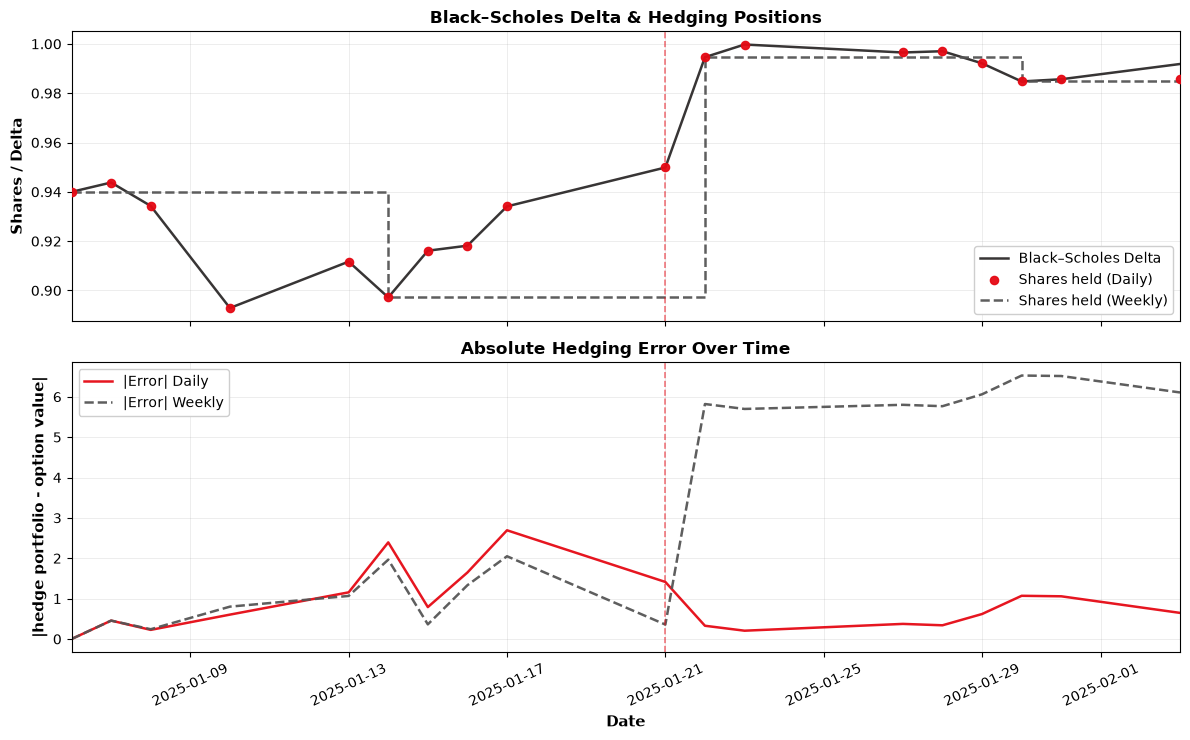

In [20]:
# Delta vs shares held (top), absolute hedging error (bottom)
fig_b, (ax3, ax4) = plt.subplots(
    2, 1, figsize=(12, 7.5), sharex=True, gridspec_kw={"height_ratios": [1.0, 1.0]}
)

# Reference BS delta from raw data (the 'true' continuous delta).
true_delta = path.set_index("date")["delta"]

# Panel 1: BS Delta vs the shares actually held by each strategy.
ax3.plot(
    true_delta.index,
    true_delta.values,
    color=NF_DARK,
    linewidth=1.8,
    label="Black–Scholes Delta",
    alpha=0.9,
)
ax3.scatter(
    p3_daily["date"],
    p3_daily["delta_used"],
    color=NF_RED,
    s=35,
    zorder=3,
    label="Shares held (Daily)",
    alpha=0.95,
)
ax3.step(
    p3_weekly["date"],
    p3_weekly["delta_used"],
    where="post",
    color=NF_GRAY1,
    linewidth=1.8,
    linestyle="--",
    label="Shares held (Weekly)",
    alpha=0.95,
)
ax3.axvline(earnings_date, color=NF_RED, linewidth=1.2, linestyle="--", alpha=0.55)
ax3.set_ylabel("Shares / Delta", fontsize=11, fontweight="bold")
ax3.set_title("Black–Scholes Delta & Hedging Positions", fontsize=12, fontweight="bold")
ax3.legend(loc="lower right", fontsize=10, framealpha=0.95)
ax3.set_xlim(date_min, date_max)
ax3.grid(True, alpha=0.25, linestyle="-", linewidth=0.5, color=NF_GRAY2)

# Panel 2: Absolute hedging error over time (magnitude view).
ax4.plot(
    p3_daily["date"],
    p3_daily["hedging_error"].abs(),
    color=NF_RED,
    linewidth=1.8,
    label="|Error| Daily",
    alpha=0.95,
)
ax4.plot(
    p3_weekly["date"],
    p3_weekly["hedging_error"].abs(),
    color=NF_GRAY1,
    linewidth=1.8,
    linestyle="--",
    label="|Error| Weekly",
    alpha=0.95,
)
ax4.axvline(earnings_date, color=NF_RED, linewidth=1.2, linestyle="--", alpha=0.55)
ax4.set_ylabel("|hedge portfolio - option value|", fontsize=11, fontweight="bold")
ax4.set_xlabel("Date", fontsize=11, fontweight="bold")
ax4.set_title("Absolute Hedging Error Over Time", fontsize=12, fontweight="bold")
ax4.legend(loc="upper left", fontsize=10, framealpha=0.95)
ax4.set_xlim(date_min, date_max)
ax4.tick_params(axis="x", rotation=25)
ax4.grid(True, alpha=0.25, linestyle="-", linewidth=0.5, color=NF_GRAY2)

plt.tight_layout()
plt.savefig(
    os.path.join(FIGS_DIR, "p3_delta_staleness.svg"), format="svg", bbox_inches="tight", dpi=150
)
plt.show()